<a href="https://colab.research.google.com/github/anashenkonina-collab/python_for_ds_task/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22HW_11_3_%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D1%87%D0%BD%D1%96_%D0%B2%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%97_%D0%B7_Seaborn_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour


---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

In [2]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)

In [12]:
grouped_data = df.groupby('month_year')['count']
monthly_mean = grouped_data.mean()
monthly_std = grouped_data.std()

lower_bound = monthly_mean - monthly_std
upper_bound = monthly_mean + monthly_std

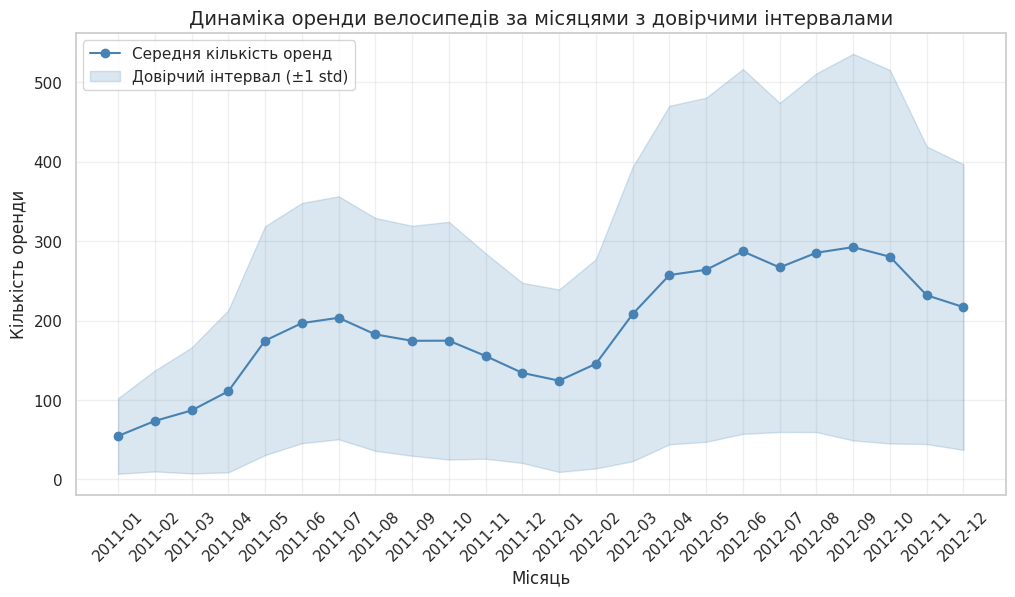

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_mean.index, monthly_mean.values, marker='o', color='steelblue', label='Середня кількість оренд')

plt.fill_between(monthly_mean.index, lower_bound, upper_bound, color='steelblue', alpha=0.2, label='Довірчий інтервал (±1 std)')

plt.title('Динаміка оренди велосипедів за місяцями з довірчими інтервалами', fontsize=14)
plt.xlabel('Місяць', fontsize=12)
plt.ylabel('Кількість оренди', fontsize=12)
plt.grid(True, linestyle='-', alpha=0.3)
plt.xticks(rotation=45)
plt.legend()
plt.show()

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

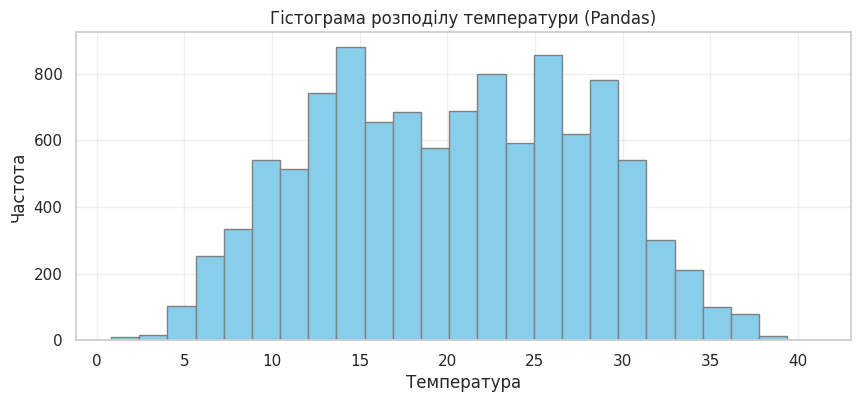

In [29]:
plt.figure(figsize=(10, 4))

df['temp'].plot(kind='hist', bins=25, color='skyblue', edgecolor='gray')

plt.title('Гістограма розподілу температури (Pandas)')
plt.xlabel('Температура')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)

plt.show()

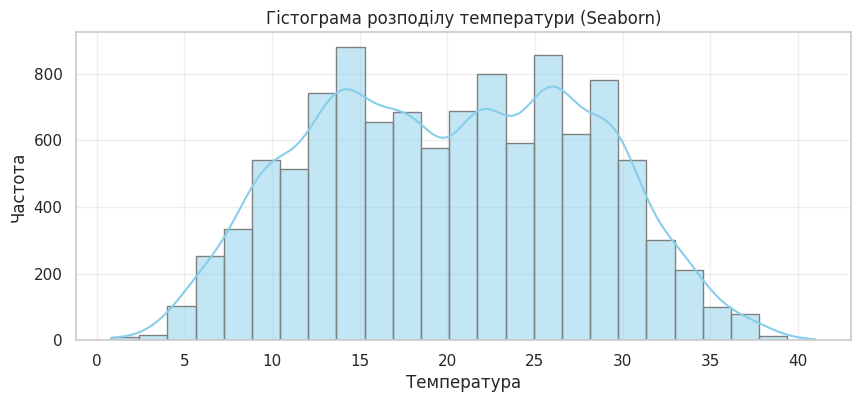

In [35]:
plt.figure(figsize=(10, 4))

sns.histplot(df['temp'], bins=25, kde=True, color='skyblue', edgecolor='gray')

plt.title('Гістограма розподілу температури (Seaborn)')
plt.xlabel('Температура')
plt.ylabel('Частота')
plt.grid(True, alpha=0.3)

plt.show()

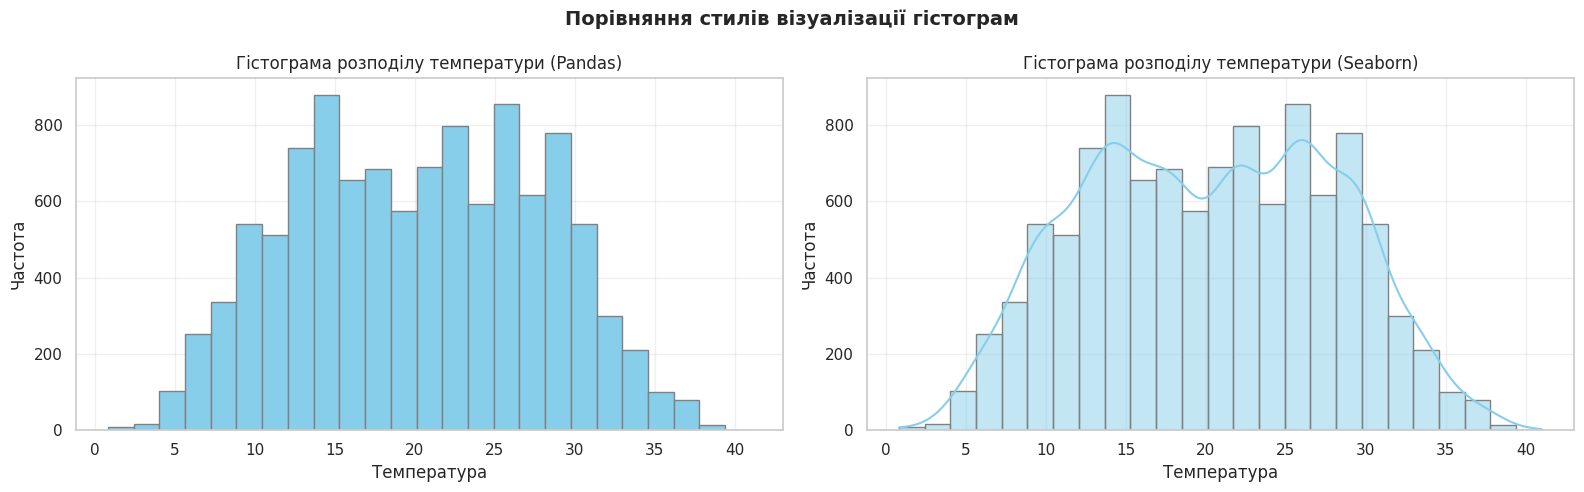

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

df['temp'].plot(kind='hist', bins=25, color='skyblue', edgecolor='gray', ax=ax[0])
ax[0].set_title('Гістограма розподілу температури (Pandas)', fontsize=12)
ax[0].set_xlabel('Температура')
ax[0].set_ylabel('Частота')
ax[0].grid(True, alpha=0.3)

sns.histplot(df['temp'], bins=25, kde=True, color='skyblue', edgecolor='gray', ax=ax[1])
ax[1].set_title('Гістограма розподілу температури (Seaborn)', fontsize=12)
ax[1].set_xlabel('Температура')
ax[1].set_ylabel('Частота')
ax[1].grid(True, alpha=0.3)

fig.suptitle('Порівняння стилів візуалізації гістограм', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


Ця плавна синя лінія називається KDE (Kernel Density Estimate — Оцінка ядерної щільності) .Як описати своїми словами: Це згладжена версія гістограми. Вона показує плавний безперервний розподіл даних, та чіткіше бачить, де знаходить головні піки, без прив’язки до конкретної кількості розмірників-бінів.

1. Дизайн: за замовчуванням Seaborn робить графіки більш сучасними та «м'якими» (палітра кольорів приємна для ока).
2. Додаткові можливості: Seaborn дозволяє в один короткий параметр ( kde=True) додати лінійну оцінку щільності, тоді як у Pandas для побудови такої лінії довелося написати окрему функцію.

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

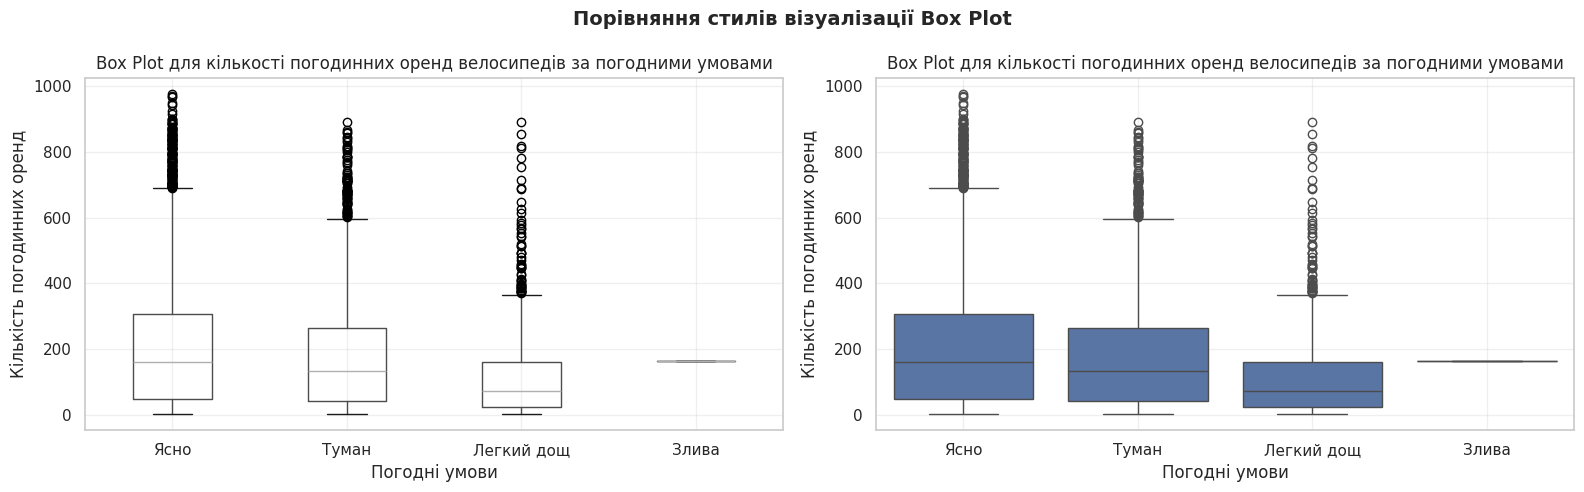

In [62]:
weather_labels = ['Ясно', 'Туман', 'Легкий дощ', 'Злива']

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

df.boxplot(column='count', by='weather', ax=ax[0])
ax[0].set_title('Box Plot для кількості погодинних оренд велосипедів за погодними умовами', fontsize=12)
ax[0].set_xlabel('Погодні умови')
ax[0].set_ylabel('Кількість погодинних оренд')
ax[0].grid(True, alpha=0.3)
ax[0].set_xticks([1, 2, 3, 4])
ax[0].set_xticklabels(weather_labels)
fig.suptitle('')

sns.boxplot(data=df, x = 'weather', y = 'count')
ax[1].set_title('Box Plot для кількості погодинних оренд велосипедів за погодними умовами', fontsize=12)
ax[1].set_xlabel('Погодні умови')
ax[1].set_ylabel('Кількість погодинних оренд')
ax[1].grid(True, alpha=0.3)
ax[1].set_xticks([0, 1, 2, 3])
ax[1].set_xticklabels(weather_labels)

fig.suptitle('Порівняння стилів візуалізації Box Plot', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

Дизайн: за замовчуванням Seaborn робить графіки більш сучасними та «м'якими» (палітра кольорів приємна для ока).


<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


In [69]:
numeric_df = df.select_dtypes(include=['number'])

corr_matrix = numeric_df.corr()
corr_matrix


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day,week,weekday_num,year,month,hour
season,1.000000,0.029368,-0.008126,0.008879,0.258689,0.264744,0.190610,-0.147121,0.096758,0.164011,0.163439,0.001729,0.939284,-0.010553,-0.004797,0.971524,-0.006546
holiday,0.029368,1.000000,-0.250491,-0.007074,0.000295,-0.005215,0.001929,0.008409,0.043799,-0.020956,-0.005393,-0.015877,0.000976,-0.191832,0.012021,0.001731,-0.000354
workingday,-0.008126,-0.250491,1.000000,0.033772,0.029966,0.024660,-0.010880,0.013373,-0.319111,0.119460,0.011594,0.009829,-0.022593,-0.704267,-0.002482,-0.003394,0.002780
weather,0.008879,-0.007074,0.033772,1.000000,-0.055035,-0.055376,0.406244,0.007261,-0.135918,-0.109340,-0.128655,-0.007890,0.019762,-0.047692,-0.012548,0.012144,-0.022740
temp,0.258689,0.000295,0.029966,-0.055035,1.000000,0.984948,-0.064949,-0.017852,0.467097,0.318571,0.394454,0.015551,0.240794,-0.038466,0.061226,0.257589,0.145430
atemp,0.264744,-0.005215,0.024660,-0.055376,0.984948,1.000000,-0.043536,-0.057473,0.462067,0.314635,0.389784,0.011866,0.248653,-0.040235,0.058540,0.264173,0.140343
humidity,0.190610,0.001929,-0.010880,0.406244,-0.064949,-0.043536,1.000000,-0.318607,-0.348187,-0.265458,-0.317371,-0.011335,0.216435,-0.026507,-0.078606,0.204537,-0.278011
windspeed,-0.147121,0.008409,0.013373,0.007261,-0.017852,-0.057473,-0.318607,1.000000,0.092276,0.091052,0.101369,0.036157,-0.145962,-0.024804,-0.015221,-0.150192,0.146631
casual,0.096758,0.043799,-0.319111,-0.135918,0.467097,0.462067,-0.348187,0.092276,1.000000,0.497250,0.690414,0.014109,0.079906,0.246959,0.145241,0.092722,0.302045
registered,0.164011,-0.020956,0.119460,-0.109340,0.318571,0.314635,-0.265458,0.091052,0.497250,1.000000,0.970948,0.019111,0.156480,-0.084427,0.264265,0.169451,0.380540


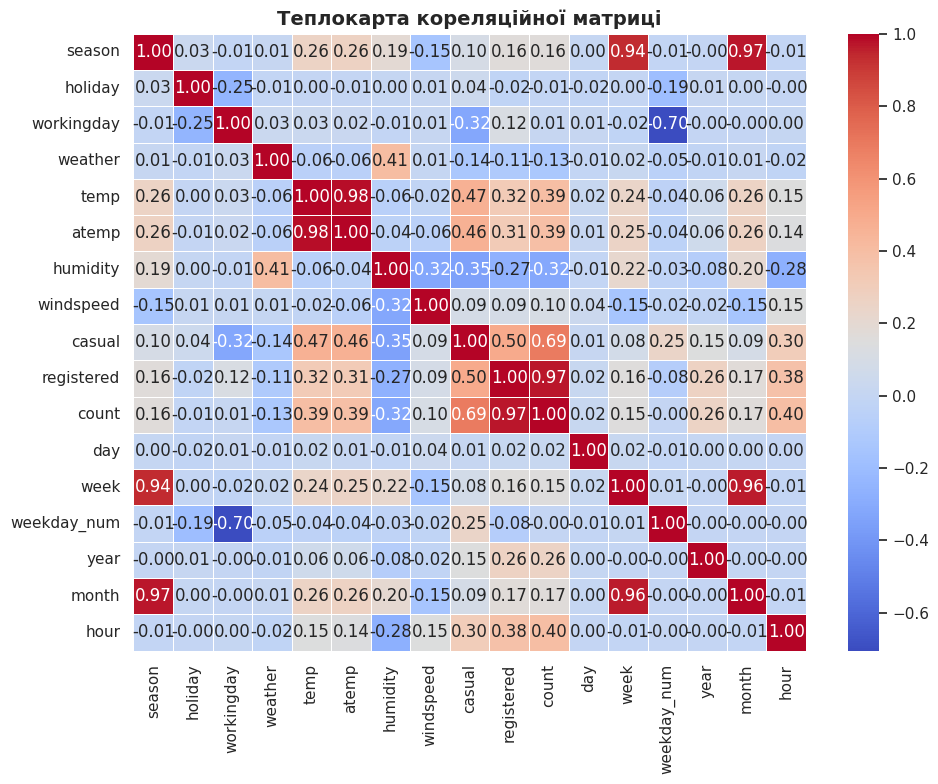

In [68]:
plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)

plt.title('Теплокарта кореляційної матриці', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


1.
registered(0,97): Це найвища кореляція, загальна кількість облікових записів складається із зареєстрованих користувачів.
casual(0,69): Сильний позитивний зв’язок — випадкові (незареєстровані) клієнти суттєво збільшують загальний показник.
hour(0.40): Година отримала помітне значення на оренду
temp(0,39) та atemp(0,39): Температура має вагомий вплив. Чим тепліше на вулицях, тим більше людей орендують велосипеди.

2.
Між ними позитивна кореляція (0.98). temp — це фактична температура повітря, а atemp — ця температура, яка відчувається людиною (з урахуванням вологості та вітру). Ці два показники майже повністю дублюють один одного.

3.
weekday_numта workingday(-0,70) — вихідні дні за логікою протилежні робочим дням
humidityта casual(-0.35). Випадкові користувачі надзвичайно сильно залежать від вологи повітря
humidityта count(-0.32) . Чим вище вологість, тим менше людей хочуть брати велосипеди
workingdayта casual(-0,32) — у робочі дні кількість оренд різко зменшується
weatherта count(-0.13) . Чим більша цифра в weather, тим гірша погода, тобто оренди падають.


## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


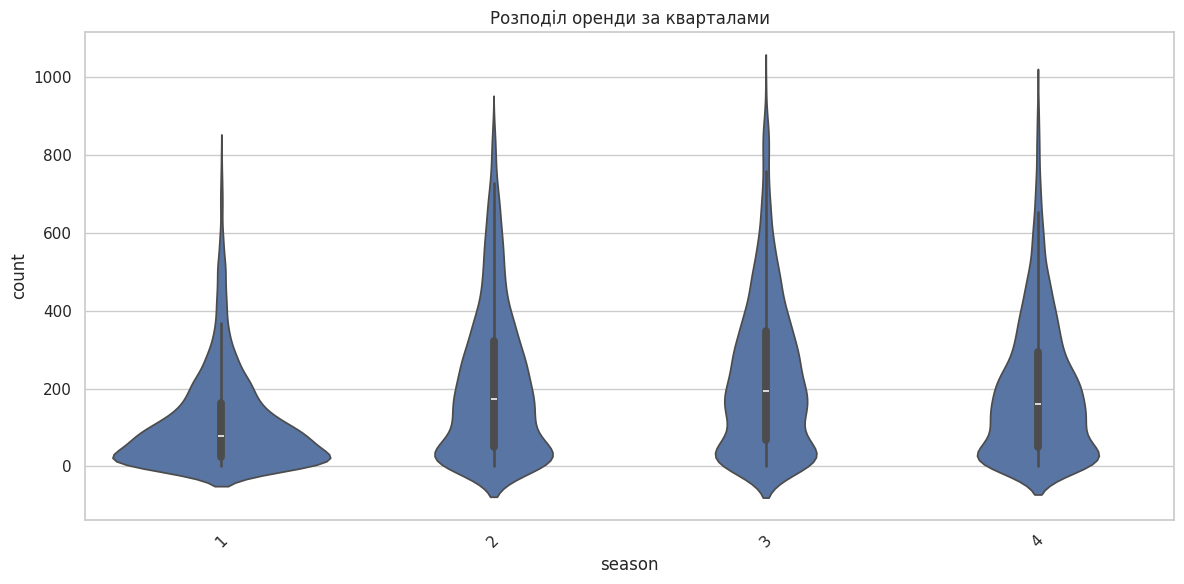

In [71]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='season', y='count')
plt.xticks(rotation=45)
plt.title('Розподіл оренди за кварталами')
plt.tight_layout()
plt.show()

1. Товщина (або ширина) «скрипки» в конкретній точці показує щільність розподілу даних (частоту). Простими словами — чим ширша фігура по горизонталі на певному рівні, тим більше днів/год має саме таку кількість оренди.
2. Найбільша варіабельність у 3-му кварталі
3. Головна перевага тому, що violin plot поєднує в собі класичний box plot та гістограму

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

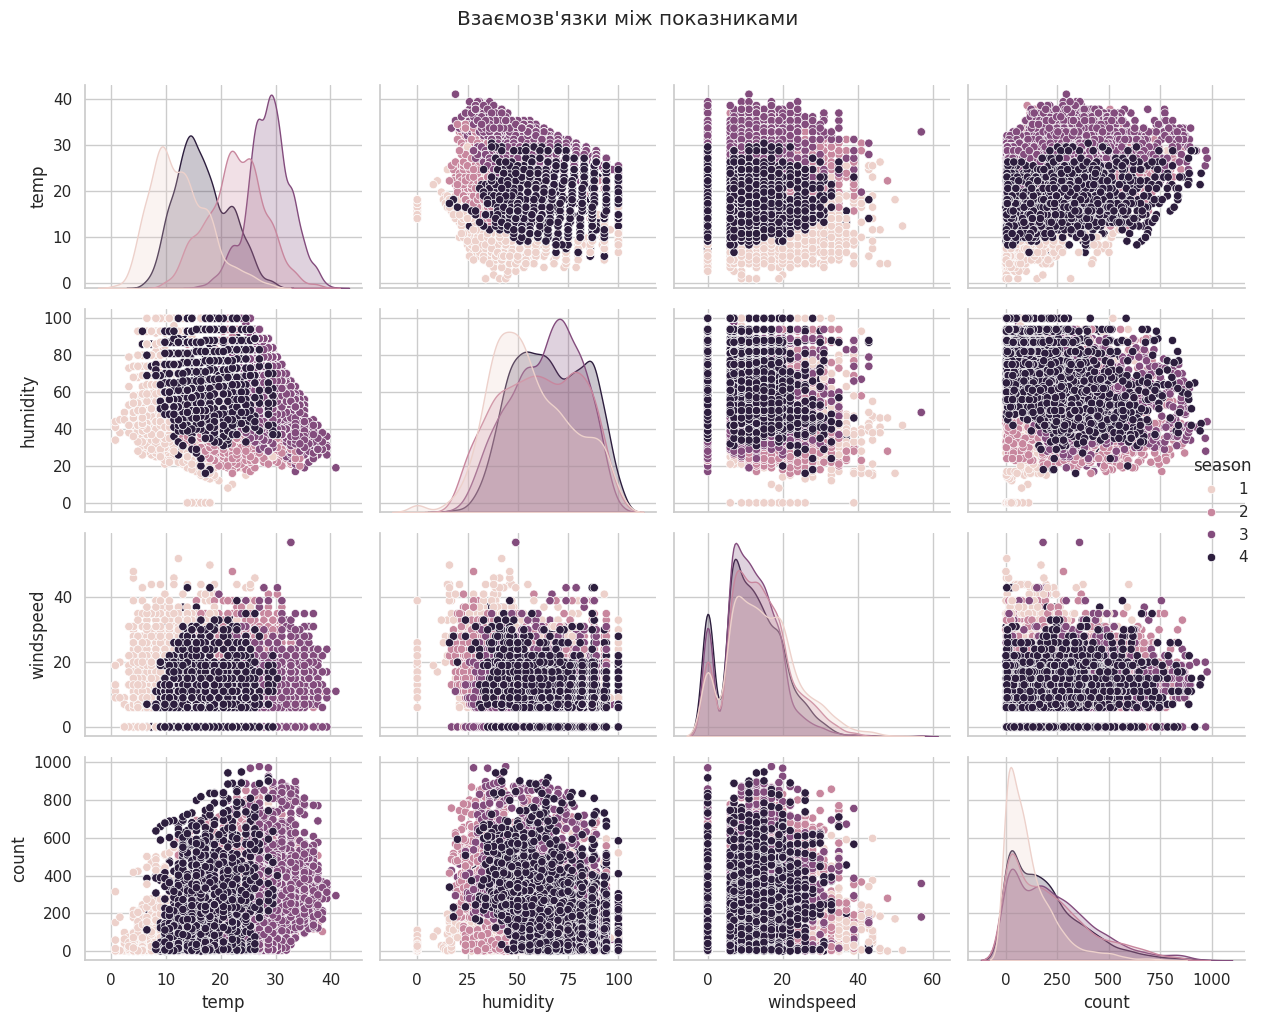

In [75]:
sample_df = data[['temp', 'humidity', 'windspeed', 'count', 'season']]
sns.pairplot(sample_df, hue='season', height=2.5, aspect=1.2)
plt.suptitle('Взаємозв\'язки між показниками', y=1.02)
plt.tight_layout()
plt.show()

1. Найсильніший лінійний зв'язок видно на перетині tempта count
2. Найсильніше між кварталами різні temp

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

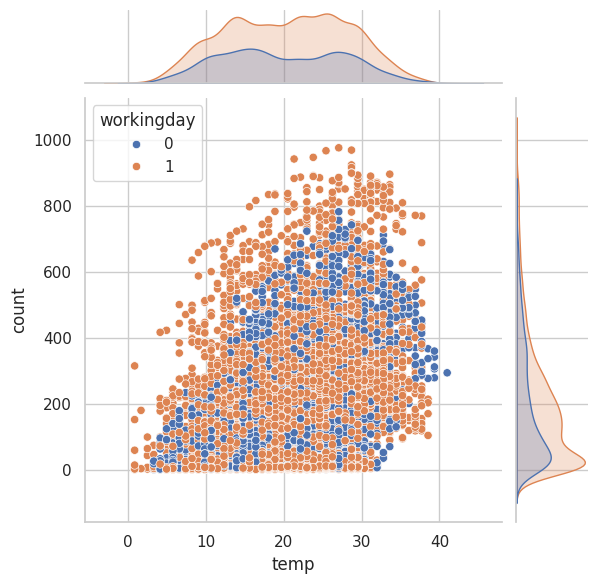

In [76]:
sns.jointplot(data=df, x = 'temp', y = 'count', hue = 'workingday');

1. Графіки по краях (зверху та праворуч) показують одновимірні розподіли щільності для кожної зміни окремо
   Верхній графік показує розподіл температури
   Правий графік показує розподіл кількості оренд
2. Так, різниця є, і вона чітко помітна в пікових значеннях (у верхній частині графіка).   